# 31 — Controlled vertical-scale sensitivity

Diagnose the physical mismatches found in [notebook 30](30_similarity_error_analysis.ipynb). Change the **vertical scale** of the same terrain, holding horizontal geometry, input normalization and model weights fixed. This is a counterfactual sensitivity experiment, not new source data or relevance labels.

Read the saved four CNN variants and reconstruct their untrained controls with the original seed. Use notebook 29's fixed query sample from existing development regions. No retraining, parameter selection or final-reserve access occurs. Trained-region and development-holdout results remain separate.

## Intervention and controls

Use height factors **0.5, 0.75, 1, 1.25, 1.5 and 2**. These are diagnostic perturbations, not equipment limits or recommended training augmentations.

For a positive factor `f`, relative elevation and local elevation SD multiply by `f`. Slopes change to `degrees(atan(f * tan(radians(slope))))`, consistent with multiplying the elevation surface at fixed horizontal spacing. This corresponds to scaling the surrounding derivative context as well; do not recalculate derivatives from an unpadded crop. Keep support masks and the original training-fitted scaler fixed.

Factor 1 is an identity control. A 90° rotation is a second control: the existing inference function averages all four rotations, so its embedding should be unchanged within numerical tolerance. Flat terrain may remain unchanged under vertical scaling; report its original relief rather than interpreting it as a failed sensitivity test.

Measure cosine similarity and unit-vector displacement from the original. Calibrate displacement by the original embedding's median distance to sampled patches from other regions of the same body. This descriptive reference helps interpret an untrained encoder whose vectors may all be very close together; it is not a learned transform or a relevance threshold.

In [7]:
import json
import os
import sys
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "outline.md").exists())
sys.path.insert(0, str(ROOT))
from notebooks.shared.analysis_artifacts import rebase_links
from notebooks.shared.inspection import check_input, file_hash, verify_run
from notebooks.modeling.terrain_similarity.model_weights import check_checkpoint
from notebooks.modeling.terrain_similarity.similarity_cnn import TerrainSimilarityCNN, cosine_top_k
from notebooks.modeling.terrain_similarity.similarity_experiment import embed
from notebooks.modeling.terrain_similarity.terrain_dataset import validate_config
from notebooks.modeling.terrain_similarity.terrain_learning import normalize_tensors
from notebooks.modeling.terrain_similarity.terrain_perturbation import rescale_terrain

SOURCE = ROOT / "data/processed/terrain_similarity_cnn/20261101T082707986851Z_5413e6"
DATASET = ROOT / "data/processed/terrain_learning_readiness/20261101T064233918547Z_4a05ac"
NOTEBOOK = ROOT / "notebooks/modeling/terrain_similarity/31_vertical_scale_sensitivity.ipynb"
FACTORS = [.5, .75, 1., 1.25, 1.5, 2.]
DEVICE = torch.device("cuda:0")
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
torch.set_num_threads(4)
OUT = ROOT / "data/processed/analysis" / ("vertical-sensitivity-" + datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ"))
OUT.mkdir(parents=True, exist_ok=False)
expected = {**verify_run(SOURCE), **verify_run(DATASET)}
evidence = {str(p): file_hash(p) for p in [SOURCE / "provenance.json", DATASET / "provenance.json", NOTEBOOK,
            *(ROOT / "notebooks" / name for name in ["modeling/terrain_similarity/model_weights.py", "modeling/terrain_similarity/similarity_cnn.py", "modeling/terrain_similarity/similarity_experiment.py", "modeling/terrain_similarity/terrain_learning.py",
                                                    "modeling/terrain_similarity/terrain_perturbation.py", "modeling/terrain_similarity/terrain_dataset.py", "shared/inspection.py"])]}
source_manifest = json.loads((SOURCE / "provenance.json").read_text(encoding="utf-8"))
dataset_manifest = json.loads((DATASET / "provenance.json").read_text(encoding="utf-8"))
validate_config(dataset_manifest["config"])
assert dataset_manifest["config"]["patch_size_m"] == 960
assert str(torch.__version__) == source_manifest["torch"]
patches = pd.read_csv(check_input(DATASET / "patches.csv", expected, evidence)).set_index("patch_id", verify_integrity=True)
roles = {(item["body"], item["region"]): item["fold"] for item in dataset_manifest["config"]["regions"]}
for item in patches[["body", "region", "role", "fold"]].drop_duplicates().to_dict("records"):
    assert item["role"] == "development" and roles.get((item["body"], item["region"])) == item["fold"]
provenance = {"status": "running", "source_run": str(SOURCE.relative_to(ROOT)), "dataset": str(DATASET.relative_to(ROOT)),
              "factors": FACTORS, "device": str(DEVICE), "torch": str(torch.__version__), "numpy": np.__version__,
              "python": sys.version, "role": "development diagnostics; no training or relevance validation",
              "retrieval_case": "both-heldout only; original opposite-body heldout pool fixed",
              "aggregation": "median within region, then mean across regions; training and holdout kept separate",
              "reserves_opened": False}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")

736

## Evaluate fixed models on consistent physical perturbations

Validate restored and reconstructed embeddings against the saved vectors before intervention. For each model, measure the rotation control and all six scale factors on the same sampled patches. All three channels change together in physical units **before** the fixed training normalization.

For the 32 held-out Earth and 32 held-out lunar queries per variant, also search the same opposite-body held-out candidate pool used in notebook 29. Compare top-one identity and top-five overlap with this diagnostic's unperturbed ranking, computed with the same inference and precision. Record candidate relief and whether the changed query relief lies outside the candidate pool's relief range; an unavailable counterpart is a separate limitation.

In [8]:
sensitivity_rows, retrieval_rows, control_rows = [], [], []
shard_cache = {}
for view in ["full_context", "image_supported"]:
    query_manifest = pd.read_csv(check_input(SOURCE / view / "evaluation_queries.csv", expected, evidence))
    selected = patches.loc[query_manifest["patch_id"]].copy()
    for field in ["body", "region", "fold"]:
        np.testing.assert_array_equal(selected[field], query_manifest[field])
    assert selected["view"].isin(["natural_screen", view]).all() and selected.index.is_unique
    physical = np.empty((len(selected), 3, 32, 32), dtype=np.float32)
    for index, item in enumerate(selected.to_dict("records")):
        shard = item["shard"]
        if shard not in shard_cache:
            with np.load(check_input(DATASET / shard, expected, evidence), allow_pickle=False) as stored:
                assert stored["valid"].all()
                shard_cache[shard] = stored["physical"].copy()
        physical[index] = shard_cache[shard][int(item["tensor_index"])]
    relief = np.quantile(physical[:, 0], [.05, .95], axis=(1, 2)).T
    original_relief = relief[:, 1] - relief[:, 0]
    np.testing.assert_allclose(original_relief, selected["central_relief_m"], atol=1e-4, rtol=1e-6)
    for sampling in ["region_balanced", "count_weighted"]:
        folder = SOURCE / view / sampling
        preprocessing = json.loads(check_input(folder / "preprocessing.json", expected, evidence).read_text(encoding="utf-8"))
        scaler = preprocessing["scaler"]
        assert preprocessing["dataset_run"] == str(DATASET.relative_to(ROOT)).replace("\\", "/")
        assert scaler["channels"] == ["relative_elevation_m", "slope_deg", "local_elevation_std_m"]
        normalized, valid = normalize_tensors(physical, np.array(scaler["mean"]), np.array(scaler["scale"]))
        assert valid.all()
        with np.load(check_input(folder / "embeddings.npz", expected, evidence), allow_pickle=False) as stored:
            bank_ids = stored["patch_ids"].copy()
            banks = {method: stored[method].copy() for method in ["cnn", "random_encoder"]}
        bank_metadata = patches.loc[bank_ids]
        assert bank_metadata["view"].isin(["natural_screen", view]).all()
        selected_indices = bank_metadata.index.get_indexer(selected.index)
        assert (selected_indices >= 0).all()
        for method in ["cnn", "random_encoder"]:
            torch.manual_seed(source_manifest["config"]["seed"])
            model = TerrainSimilarityCNN().to(DEVICE)
            if method == "cnn":
                checkpoint = check_checkpoint(ROOT, SOURCE, view, sampling, expected, evidence)
                model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
            original = embed(model, normalized, DEVICE)
            np.testing.assert_allclose(original, banks[method][selected_indices], atol=1e-5, rtol=1e-5)
            rotated = embed(model, np.rot90(normalized, 1, axes=(-2, -1)).copy(), DEVICE)
            rotation_error = np.linalg.norm(rotated - original, axis=1)
            assert rotation_error.max() < 1e-5
            original_unit = original.astype(np.float64)
            original_unit /= np.linalg.norm(original_unit, axis=1, keepdims=True)
            reference_distances = np.sqrt(np.maximum(0., 2. - 2. * np.clip(original_unit @ original_unit.T, -1., 1.)))
            reference = []
            for item_index, item in enumerate(selected.to_dict("records")):
                other = (selected["body"].to_numpy() == item["body"]) & (selected["region"].to_numpy() != item["region"])
                assert other.any()
                reference.append(float(np.median(reference_distances[item_index, other])))
            reference = np.array(reference)
            assert (reference > 1e-8).all()
            control_rows.append({"view": view, "sampling": sampling, "method": method,
                                 "max_rotation_displacement": float(rotation_error.max()),
                                 "max_saved_embedding_difference": float(np.abs(original - banks[method][selected_indices]).max())})
            for factor in FACTORS:
                altered = rescale_terrain(physical, factor)
                transformed, valid = normalize_tensors(altered, np.array(scaler["mean"]), np.array(scaler["scale"]))
                assert valid.all()
                vectors = embed(model, transformed, DEVICE)
                unit = vectors.astype(np.float64)
                unit /= np.linalg.norm(unit, axis=1, keepdims=True)
                displacement = np.linalg.norm(unit - original_unit, axis=1)
                similarity = np.clip(np.sum(unit * original_unit, axis=1), -1., 1.)
                if factor == 1.:
                    assert displacement.max() < 1e-6
                changed_p90 = np.quantile(altered[:, 1], .9, axis=(1, 2))
                for index, (patch_id, item) in enumerate(zip(selected.index, selected.to_dict("records"), strict=True)):
                    identity = {"view": view, "sampling": sampling, "method": method, "factor": factor,
                                "patch_id": patch_id, "body": item["body"], "region": item["region"], "fold": item["fold"]}
                    sensitivity_rows.append({**identity, "original_relief_m": original_relief[index],
                                             "changed_relief_m": original_relief[index] * factor,
                                             "changed_slope_p90_deg": changed_p90[index], "cosine_to_original": similarity[index],
                                             "embedding_displacement": displacement[index], "other_region_reference_distance": reference[index],
                                             "relative_displacement": displacement[index] / reference[index]})
                    if item["fold"] != "holdout":
                        continue
                    pool = np.flatnonzero((bank_metadata["body"].to_numpy() != item["body"]) & (bank_metadata["fold"].to_numpy() == "holdout"))
                    ids = bank_metadata.index[pool].tolist()
                    before, _ = cosine_top_k(original[index], banks[method][pool], ids, 5)
                    after, _ = cosine_top_k(vectors[index], banks[method][pool], ids, 5)
                    overlap = len(set(before) & set(after)) / 5
                    if factor == 1.:
                        assert np.array_equal(before, after)
                    candidate_reliefs = bank_metadata.iloc[pool]["central_relief_m"].to_numpy()
                    changed_relief = original_relief[index] * factor
                    retrieval_rows.append({**identity, "direction": item["body"] + "_to_" + ("moon" if item["body"] == "earth" else "earth"),
                                           "top1_changed": bool(before[0] != after[0]), "top5_overlap": overlap,
                                           "before_candidate_id": ids[before[0]], "after_candidate_id": ids[after[0]],
                                           "before_candidate_relief_m": candidate_reliefs[before[0]],
                                           "after_candidate_relief_m": candidate_reliefs[after[0]], "changed_query_relief_m": changed_relief,
                                           "after_abs_relief_error_m": abs(candidate_reliefs[after[0]] - changed_relief),
                                           "outside_pool_relief_range": bool(changed_relief < candidate_reliefs.min() or changed_relief > candidate_reliefs.max())})
            print(view, sampling, method, "checked")


full_context region_balanced cnn checked
full_context region_balanced random_encoder checked
full_context count_weighted cnn checked
full_context count_weighted random_encoder checked
image_supported region_balanced cnn checked
image_supported region_balanced random_encoder checked
image_supported count_weighted cnn checked
image_supported count_weighted random_encoder checked


## Regional sensitivity and ranking response

Lower cosine similarity or larger displacement means the representation responds to vertical scaling. It does **not** show whether its distance is appropriate for a mission. Larger relative displacement means the perturbation moves an embedding farther compared with typical separation from the sampled other-region terrain.

Rank changes show sensitivity but not improvement. A ranking can change while selecting a candidate with an even larger relief mismatch. Candidate-range flags identify some infeasible counterpart cases; being inside the range does not guarantee a relevant candidate exists. Separate training-region diagnostics from the two already-explored holdout regions.

In [9]:
sensitivity = pd.DataFrame(sensitivity_rows)
retrieval = pd.DataFrame(retrieval_rows)
controls = pd.DataFrame(control_rows)
sensitivity.to_csv(OUT / "patch_sensitivity.csv", index=False)
retrieval.to_csv(OUT / "retrieval_response.csv", index=False)
controls.to_csv(OUT / "controls.csv", index=False)
keys = ["view", "sampling", "method", "factor", "body", "fold"]
metrics = ["cosine_to_original", "embedding_displacement", "relative_displacement"]
regional = sensitivity.groupby(keys + ["region"], as_index=False)[metrics].median()
macro = regional.groupby(keys, as_index=False)[metrics].mean()
regional.to_csv(OUT / "sensitivity_by_region.csv", index=False)
macro.to_csv(OUT / "sensitivity_region_macro.csv", index=False)
response = retrieval.groupby(["view", "sampling", "method", "factor", "direction"], as_index=False).agg(
    top1_changed_fraction=("top1_changed", "mean"), mean_top5_overlap=("top5_overlap", "mean"),
    median_after_relief_error_m=("after_abs_relief_error_m", "median"), outside_pool_relief_fraction=("outside_pool_relief_range", "mean"))
response.to_csv(OUT / "retrieval_response_summary.csv", index=False)
display(controls)
display(macro.loc[(macro["factor"] == 2.) & (macro["fold"] == "holdout")])
display(response.loc[response["factor"] == 2.])

,view,sampling,method,max_rotation_displacement,max_saved_embedding_difference
0,full_context,region_balanced,cnn,1.370645e-07,0.000000e+00
1,full_context,region_balanced,random_encoder,1.188413e-07,0.000000e+00
2,full_context,count_weighted,cnn,1.207788e-07,0.000000e+00
3,full_context,count_weighted,random_encoder,1.188413e-07,0.000000e+00
4,image_supported,region_balanced,cnn,1.482912e-07,2.086163e-07
5,image_supported,region_balanced,random_encoder,1.108822e-07,2.980232e-08
6,image_supported,count_weighted,cnn,1.055655e-07,2.402812e-07
7,image_supported,count_weighted,random_encoder,1.108822e-07,2.980232e-08


,view,sampling,method,factor,body,fold,cosine_to_original,embedding_displacement,relative_displacement
20,full_context,count_weighted,cnn,2.0,earth,holdout,0.261576,1.215230,0.885498
22,full_context,count_weighted,cnn,2.0,moon,holdout,0.087007,1.351290,0.934221
44,full_context,count_weighted,random_encoder,2.0,earth,holdout,0.999909,0.013484,1.807586
46,full_context,count_weighted,random_encoder,2.0,moon,holdout,0.997956,0.063935,2.493268
68,full_context,region_balanced,cnn,2.0,earth,holdout,0.080839,1.355847,0.956225
70,full_context,region_balanced,cnn,2.0,moon,holdout,0.000588,1.413797,1.002355
92,full_context,region_balanced,random_encoder,2.0,earth,holdout,0.999909,0.013484,1.807586
94,full_context,region_balanced,random_encoder,2.0,moon,holdout,0.997956,0.063935,2.493268
116,image_supported,count_weighted,cnn,2.0,earth,holdout,0.306919,1.177305,0.870605
118,image_supported,count_weighted,cnn,2.0,moon,holdout,0.218489,1.250128,0.929989


,view,sampling,method,factor,direction,top1_changed_fraction,mean_top5_overlap,median_after_relief_error_m,outside_pool_relief_fraction
10,full_context,count_weighted,cnn,2.0,earth_to_moon,0.90625,0.16875,28.651440,0.12500
11,full_context,count_weighted,cnn,2.0,moon_to_earth,1.00000,0.02500,98.570923,0.25000
22,full_context,count_weighted,random_encoder,2.0,earth_to_moon,0.84375,0.29375,14.562061,0.12500
23,full_context,count_weighted,random_encoder,2.0,moon_to_earth,1.00000,0.00000,32.306494,0.25000
34,full_context,region_balanced,cnn,2.0,earth_to_moon,0.87500,0.14375,39.731285,0.12500
35,full_context,region_balanced,cnn,2.0,moon_to_earth,1.00000,0.00000,125.827600,0.25000
46,full_context,region_balanced,random_encoder,2.0,earth_to_moon,0.84375,0.29375,14.562061,0.12500
47,full_context,region_balanced,random_encoder,2.0,moon_to_earth,1.00000,0.00000,32.306494,0.25000
58,image_supported,count_weighted,cnn,2.0,earth_to_moon,0.90625,0.41250,101.399916,0.40625
59,image_supported,count_weighted,cnn,2.0,moon_to_earth,0.96875,0.09375,188.672363,0.78125


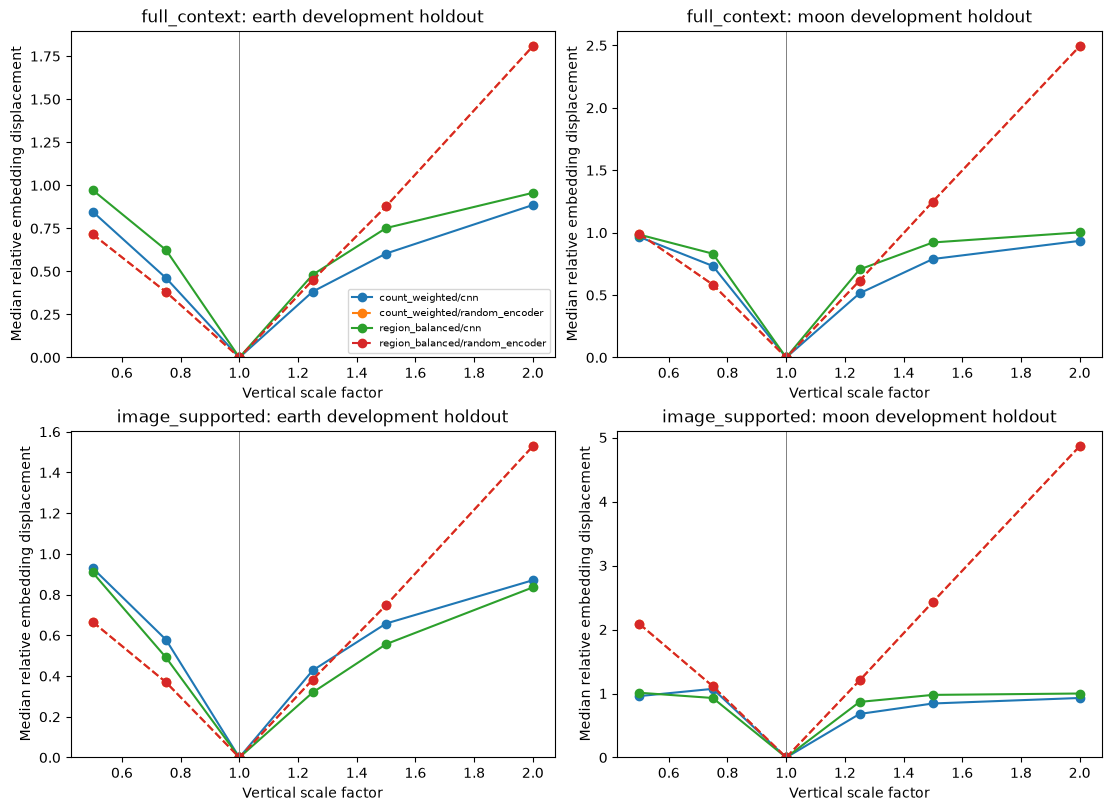

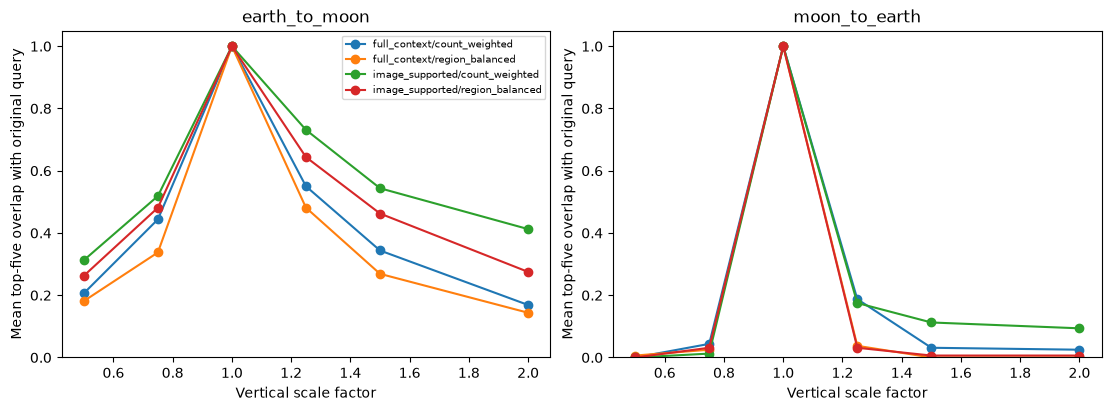

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
for row, view in enumerate(["full_context", "image_supported"]):
    for column, body in enumerate(["earth", "moon"]):
        part = macro.loc[(macro["view"] == view) & (macro["body"] == body) & (macro["fold"] == "holdout")]
        for (sampling, method), group in part.groupby(["sampling", "method"]):
            group = group.sort_values("factor")
            axes[row, column].plot(group["factor"], group["relative_displacement"], marker="o",
                                   linestyle="-" if method == "cnn" else "--", label=f"{sampling}/{method}")
        axes[row, column].set(title=f"{view}: {body} development holdout", xlabel="Vertical scale factor",
                              ylabel="Median relative embedding displacement", ylim=(0, None))
        axes[row, column].axvline(1, color="grey", linewidth=.7)
axes[0, 0].legend(fontsize=7)
fig.savefig(OUT / "relative_sensitivity.png", dpi=130)
plt.show()
plt.close(fig)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, direction in zip(axes, ["earth_to_moon", "moon_to_earth"], strict=True):
    for (view, sampling), group in response.loc[(response["method"] == "cnn") & (response["direction"] == direction)].groupby(["view", "sampling"]):
        group = group.sort_values("factor")
        ax.plot(group["factor"], group["mean_top5_overlap"], marker="o", label=f"{view}/{sampling}")
    ax.set(title=direction, xlabel="Vertical scale factor", ylabel="Mean top-five overlap with original query", ylim=(0, 1.05))
axes[0].legend(fontsize=7)
fig.savefig(OUT / "ranking_response.png", dpi=130)
plt.show()
plt.close(fig)

## How to interpret the result

If embeddings barely move after substantial physical changes, investigate insufficient amplitude sensitivity. If embeddings move and rankings change, that rules out complete insensitivity for the tested patches; it does not prove that learned distances rank physical fidelity correctly. Compare relative displacement, actual candidate relief and available candidate range before attributing a cause.

This experiment cannot isolate which architectural component or training objective caused the notebook-30 errors. Rotation-averaged embeddings, the cosine metric, false-negative training pairs and missing cross-body relevance supervision remain possible contributors. Do not assume that more epochs or removing normalization will fix the problem.

Any next model change should be a controlled comparison guided by the observed results and an independent relevance rubric. Preserve physical descriptors as a reference and keep final reserves closed. These synthetic perturbations are not training examples or validated mission limits.

In [11]:
notebook = nbformat.read(NOTEBOOK, as_version=4)
report = "\n\n".join(cell.source for cell in notebook.cells if cell.cell_type == "markdown")
report = rebase_links(report, NOTEBOOK, OUT / "REPORT.md", {})
(OUT / "REPORT.md").write_text(report + "\n", encoding="utf-8")
provenance["inputs"] = evidence
provenance["outputs"] = {p.name: file_hash(p) for p in sorted(OUT.iterdir()) if p.is_file() and p.name != "provenance.json"}
provenance["status"] = "publishing"
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print("Complete:", OUT)
print(len(sensitivity), "perturbation records;", len(retrieval), "heldout retrieval responses; no training")


Complete: .\data\processed\analysis\vertical-sensitivity-20261102T143653542280Z
18432 perturbation records; 3072 heldout retrieval responses; no training


## Save reusable data and disposable reports
Run this final cell after the displays. Later notebooks read only the data directory; reports can be deleted and regenerated.

In [12]:
import sys

sys.path.insert(0, str(ROOT))
from notebooks.shared.analysis_artifacts import publish_analysis

REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable data:", OUT)
print("Disposable reports:", REPORT_OUT)

Reusable data: .\data\processed\analysis\vertical-sensitivity-20261102T143653542280Z
Disposable reports: .\reports\analysis\vertical-sensitivity-20261102T143653542280Z
